# 01 · Explore HPD housing complaints
**The 100-Meter Inequality: Know Before You Rent · Team BUTA · DS-GA 1007**

**Dataset:** [Housing Maintenance Code Complaints and Problems](https://data.cityofnewyork.us/d/ygpa-z7cr), from NYC's Department of Housing Preservation & Development (HPD). We downloaded January 2025 → October 2026, one parquet file per month, in `data/raw/hpd_complaints/`.

- **One row = one *problem*.** A tenant's complaint (`complaint_id`) can list several problems, for example "no heat" plus "mice".
- **Why it matters:** this is the most direct record of what goes wrong *inside* apartments. It answers **Q1** (does a building's past predict its future?) and gives the problem types we will predict in **Q5**.

**Questions for this notebook**
1. How big is the data, and is it complete?
2. What kinds of problems do tenants report?
3. Are problems concentrated in a few buildings?
4. **Preview of Q1:** do buildings with problems one year have them again the next?
5. What needs cleaning?

**Study window: January 1, 2025–October 31, 2026.** Annual comparisons should use January–October in both years. Housing prediction uses six-month histories and four-month outcomes; older figures and reports describe the previous study.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src import config, housing as H, preprocess as P
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 80)

pluto = H.clean_pluto_table()[["bbl", "is_residential", "unitsres", "yearbuilt"]]   # cleans PLUTO on first use
pluto_bbls = set(pluto["bbl"])
residential_bbls = set(pluto.loc[pluto["is_residential"], "bbl"])

## 1. Size and completeness

1,651,542 problem rows | 2025-01 → 2026-10


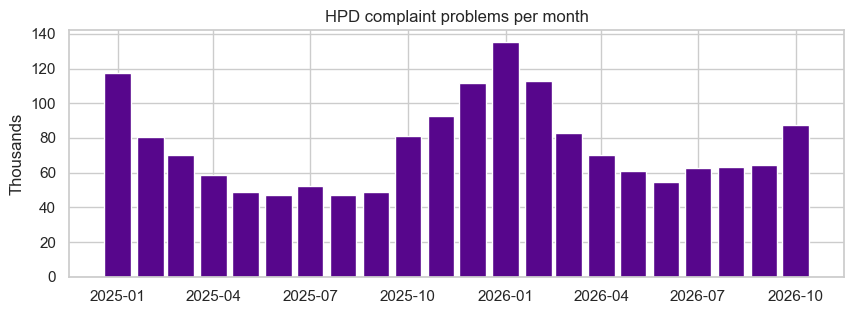

In [2]:
rows = H.monthly_rows("hpd_complaints")
print(f"{rows.sum():,} problem rows | {rows.index[0]} → {rows.index[-1]}")
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(pd.to_datetime(rows.index), rows / 1000, width=25, color=ACCENT)
ax.set(title="HPD complaint problems per month", ylabel="Thousands")
save(fig, "rent01a_hpd_complaints_per_month")

In [3]:
cols = ["received_date", "problem_id", "complaint_id", "bbl", "apartment", "unit_type", "space_type", "type",
        "major_category", "minor_category", "problem_code", "problem_status", "problem_duplicate_flag"]
c = H.load("hpd_complaints", cols)
c["received_date"] = pd.to_datetime(c["received_date"].astype(str), errors="coerce")
c["year"] = c["received_date"].dt.year
H.overview(c)

,missing_%,distinct,example
received_date,0.00,984350,2025-01-01 00:01:57
problem_id,0.00,1651542,26498995
complaint_id,0.00,1001726,13474340
bbl,0.30,77578,1020770032
apartment,0.00,13739,4A
unit_type,0.00,4,APARTMENT
space_type,0.00,33,ENTIRE APARTMENT
type,0.00,3,EMERGENCY
major_category,0.00,14,HEAT/HOT WATER
minor_category,0.00,58,APARTMENT ONLY


In [4]:
print(f"Duplicate problem_id rows: {c['problem_id'].duplicated().sum():,}")
print(f"Complaints: {c['complaint_id'].nunique():,} | problems: {len(c):,} | "
      f"problems per complaint: {len(c) / c['complaint_id'].nunique():.2f}")
print(f"Flagged as duplicate problems: {(c['problem_duplicate_flag'] == 'Y').mean():.1%}")
c["type"].value_counts(normalize=True).mul(100).round(1).to_frame("% of problems").T

Duplicate problem_id rows: 0


Complaints: 1,001,726 | problems: 1,651,542 | problems per complaint: 1.65
Flagged as duplicate problems: 16.7%


type,EMERGENCY,NON EMERGENCY,IMMEDIATE EMERGENCY
% of problems,60.60,35.30,4.10


## 2. What do tenants report?

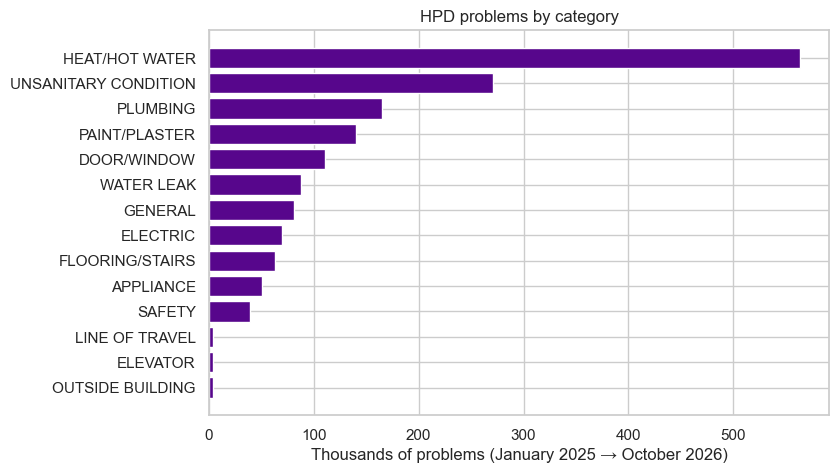

In [5]:
major = c["major_category"].value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(major.index[::-1], major.values[::-1] / 1000, color=ACCENT)
ax.set(xlabel="Thousands of problems (January 2025 → October 2026)", title="HPD problems by category")
save(fig, "rent01b_hpd_categories")

In [6]:
# The detail inside the biggest categories
(c.groupby("major_category")["minor_category"].value_counts()
   .groupby(level=0, group_keys=False).nlargest(3).to_frame("problems").head(30))

problems
major_category   minor_category                    
APPLIANCE        ELECTRIC/GAS RANGE           30171
                 REFRIGERATOR                 19954
                 MICROWAVE                       39
DOOR/WINDOW      DOOR                         61544
                 WINDOW FRAME                 34739
                 DOOR FRAME                    7526
ELECTRIC         OUTLET/SWITCH                18426
                 POWER OUTAGE                 16888
                 NO LIGHTING                  14278
ELEVATOR         MAINTENANCE                   3821
FLOORING/STAIRS  FLOOR                        60300
                 STAIRS                        2585
GENERAL          BELL/BUZZER/INTERCOM         21845
                 CABINET                      21642
                 COOKING GAS                  15267
HEAT/HOT WATER   ENTIRE BUILDING             370260
                 APARTMENT ONLY              192986
LINE OF TRAVEL   LINE OF TRAVEL                4089
OUTSIDE BUILDING ROOF DOOR/HATCH               1303
                 ROOFING                       1052
                 PAVEMENT                       606
PAINT/PLASTER    WALL                         70113
                 CEILING                      61045
                 WINDOW/FRAME                  2999
PLUMBING         WATER SUPPLY                 53348
                 BASIN/SINK                   40198
                 BATHTUB/SHOWER               32686
SAFETY           SMOKE DETECTOR               12791
                 CARBON MONOXIDE DETECTOR     10282
                 FIRE ESCAPE                   8303

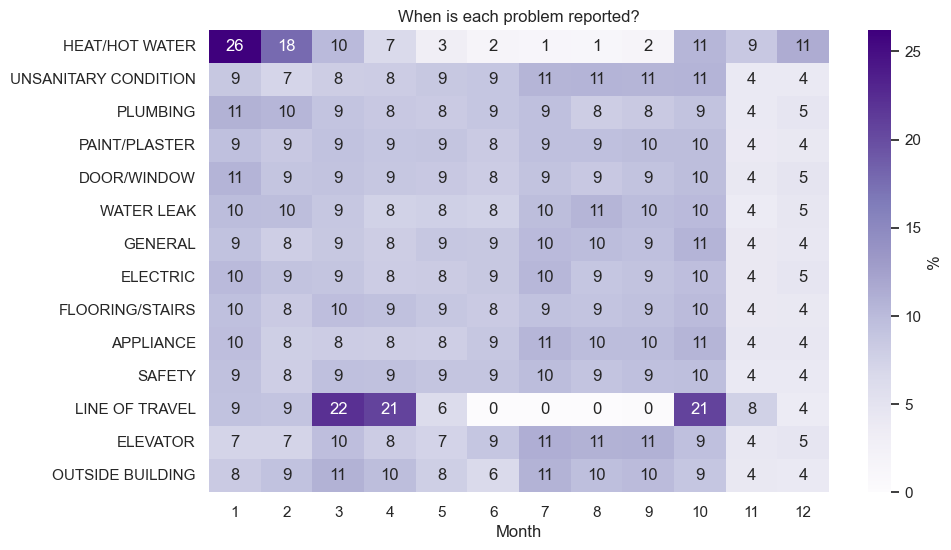

In [7]:
# Seasonality per category: share of each category's problems by calendar month
season = pd.crosstab(c["major_category"], c["received_date"].dt.month, normalize="index") * 100
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(season.loc[major.index[:14]], cmap="Purples", annot=True, fmt=".0f", ax=ax, cbar_kws={"label": "%"})
ax.set(xlabel="Month", ylabel="", title="When is each problem reported?")
save(fig, "rent01c_hpd_seasonality")

## 3. Are problems concentrated in a few buildings?

In [8]:
per_bldg = c.dropna(subset=["bbl"]).groupby("bbl").size()
print(f"Buildings with at least one problem: {len(per_bldg):,} "
      f"({len(per_bldg) / len(residential_bbls):.1%} of residential lots in PLUTO)")
display(H.concentration(per_bldg).map("{:.0%}".format).to_frame("share of all problems").T)
per_bldg.describe(percentiles=[.5, .9, .99]).to_frame("problems per building").T

Buildings with at least one problem: 77,578 (10.1% of residential lots in PLUTO)


,top 1%,top 5%,top 10%
share of all problems,23%,51%,66%


,count,mean,std,min,50%,90%,99%,max
problems per building,"77,578.00",21.24,69.80,1.00,4.00,49.00,263.00,"4,967.00"


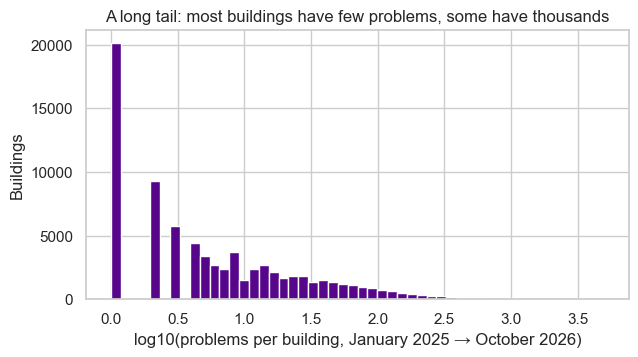

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(per_bldg), bins=50, color=ACCENT)
ax.set(xlabel="log10(problems per building, January 2025 → October 2026)", ylabel="Buildings",
       title="A long tail: most buildings have few problems, some have thousands")
save(fig, "rent01d_hpd_per_building")

## 4. Preview of Q1: does the past predict the future?
For each problem type: of the buildings that had it in Jan–Oct 2025, what share had it again in Jan–Oct 2026, compared with buildings that didn't have it in Jan–Oct 2025?

In [10]:
rows_ = []
for cat in major.index[:8]:
    ev = c[(c["received_date"].dt.month <= 10) & (c["major_category"] == cat) & c["bbl"].notna()][["bbl", "year"]]
    p = H.persistence(ev, "bbl", "year", 2025, 2026)
    had, not_had = p.iloc[:, 1].get("had problem in 2025"), p.iloc[:, 1].get("no problem in 2025")
    rows_.append({"category": cat, "P(again in Jan–Oct 2026 | had in Jan–Oct 2025)": had,
                  "P(in Jan–Oct 2026 | not in Jan–Oct 2025)*": not_had, "ratio": had / not_had if not_had else np.nan})
pd.DataFrame(rows_).set_index("category").sort_values("ratio", ascending=False)

,P(again in Jan–Oct 2026 | had in Jan–Oct 2025),P(in Jan–Oct 2026 | not in Jan–Oct 2025)*,ratio
category,,,
HEAT/HOT WATER,0.57,1.00,0.57
UNSANITARY CONDITION,0.53,1.00,0.53
PAINT/PLASTER,0.52,1.00,0.52
PLUMBING,0.50,1.00,0.50
WATER LEAK,0.50,1.00,0.50
DOOR/WINDOW,0.50,1.00,0.50
GENERAL,0.44,1.00,0.44
ELECTRIC,0.39,1.00,0.39


\* "Not in Jan–Oct 2025" here means buildings that had this problem *only in Jan–Oct 2026*, since we only see buildings that complained in one of the two years. The proper comparison against **all** residential buildings comes in modeling. Even so, a high first column already shows strong persistence.

## 5. Data quality

In [11]:
print(f"Missing BBL: {c['bbl'].isna().mean():.1%}")
print(f"BBLs matching PLUTO: {H.coverage(c['bbl'], pluto_bbls):.1%}")
print(f"Unparseable dates: {c['received_date'].isna().sum():,}")
print("Apartment field, most common values (non-apartment placeholders show up here):")
c["apartment"].value_counts().head(10).to_frame().T

Missing BBL: 0.3%


BBLs matching PLUTO: 99.7%
Unparseable dates: 0
Apartment field, most common values (non-apartment placeholders show up here):


apartment,BLDG,1,2,1A,1B,2A,2B,3A,3B,3
count,341681,44993,40743,26710,24949,23414,23052,22367,21520,19330


In [12]:
c["problem_status"].value_counts(normalize=True).mul(100).round(1).to_frame("%").T

problem_status,CLOSE,OPEN
%,98.90,1.10


## Findings

Run the cells above to inspect results for the shared January 2025–October 2026 study. Previous-window metrics are not reused.